In [ ]:
import numpy as np
import pandas as pd # data cleaning
import plotly.express as px #visulaization
import plotly.graph_objects as go #coustomize graphs
import plotly.io as pio #template coustomize
import plotly.colors as colors
pio.templates.default="plotly_white"


In [ ]:
data=pd.read_csv("/content/Sample - Superstore.csv",encoding="latin-1") # special charater kko read ke liy
data.head(1)
#data.describe() # for descriptive statsiscs
#data.info() # for more information


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136


## ** Step 1=for changeing datatype of date from object to date and time format**

In [ ]:
data['Order Date']=pd.to_datetime(data["Order Date"])
data['Ship Date']=pd.to_datetime(data['Ship Date'])

## fetch month ,days

In [ ]:
data['month']=data['Order Date'].dt.month_name()
data['day']=data['Order Date'].dt.day

data['year']=data['Order Date'].dt.year


data['month']=data['Ship Date'].dt.month_name()
data['day']=data['Ship Date'].dt.day

data['deliver time']=data['Ship Date']-data['Order Date']



## chart1

In [ ]:
a = data.groupby('month')['Sales'].sum().sort_values(ascending=False)
import plotly.express as px

fig = px.bar(
    x=a.index,
    y=a.values,
    title='Month-wise Total Sales',
    labels={'x': 'Month', 'y': 'Total Sales'}
)

fig.show()

##chart 2 Sales by category

In [ ]:
b=data.groupby('Category')['Sales'].sum().sort_values(ascending=False)
fig = px.pie(
    names=b.index,
    values=b.values,
    title='Category-wise Sales Contribution',
    hole=0.3
)
fig.update_traces(textfont_size=14,
    textinfo='label+percent',
    textfont_color='white'
)
fig.show()


##chart 3 subcategory

In [ ]:
import plotly.express as px

b = data.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=True)

# Convert sales into lakhs
b_lakhs = b / 100000

fig = px.bar(
    x=b_lakhs.values,
    y=b_lakhs.index,
    orientation='h',
    title='Sub-Category-wise Sales',
    labels={'x': 'Total Sales (Lakhs)', 'y': ''},
    text=b_lakhs.round(2)
)

fig.update_traces(
    marker_color='#2E8B57',
    texttemplate='%{text:.2f}',
    textposition='outside',
    textfont_size=11,
    cliponaxis=False
)

fig.update_layout(
    template='plotly_white',
    title_font_size=20,
    title_x=0.5,
    height=650,
    width=1000,
    margin=dict(l=120, r=100, t=80, b=60),
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(title='')
)

fig.show()

## chart 4 monthly profit

In [ ]:
import plotly.express as px

p = data.groupby('month')['Profit'].sum().reset_index()

fig = px.line(
    p,
    x='month',
    y='Profit',
    title='Monthly Profit Trend',
    markers=True,
    text='Profit'
)

fig.update_traces(
    line=dict(color='red', width=3),
    marker=dict(size=9),
    texttemplate='%{text:.2s}',
    textposition='top center'
)

fig.update_layout(
    template='plotly_white',
    title_x=0.5,
    xaxis_title='Month',
    yaxis_title='Total Profit',
    height=500
)

fig.show()

#chart 5 profit by category

In [ ]:
b=data.groupby('Category')['Profit'].sum().sort_values(ascending=False)
fig = px.pie(
    names=b.index,
    values=b.values,
    title='Category-wise Profit Contribution',
    hole=0.5,
    color_discrete_sequence=[ 'orange', 'blue',  'purple']
)


fig.update_traces(textfont_size=14,
    textinfo='label+percent',
    textfont_color='white'
)
fig.show()


Chart 6 sub category

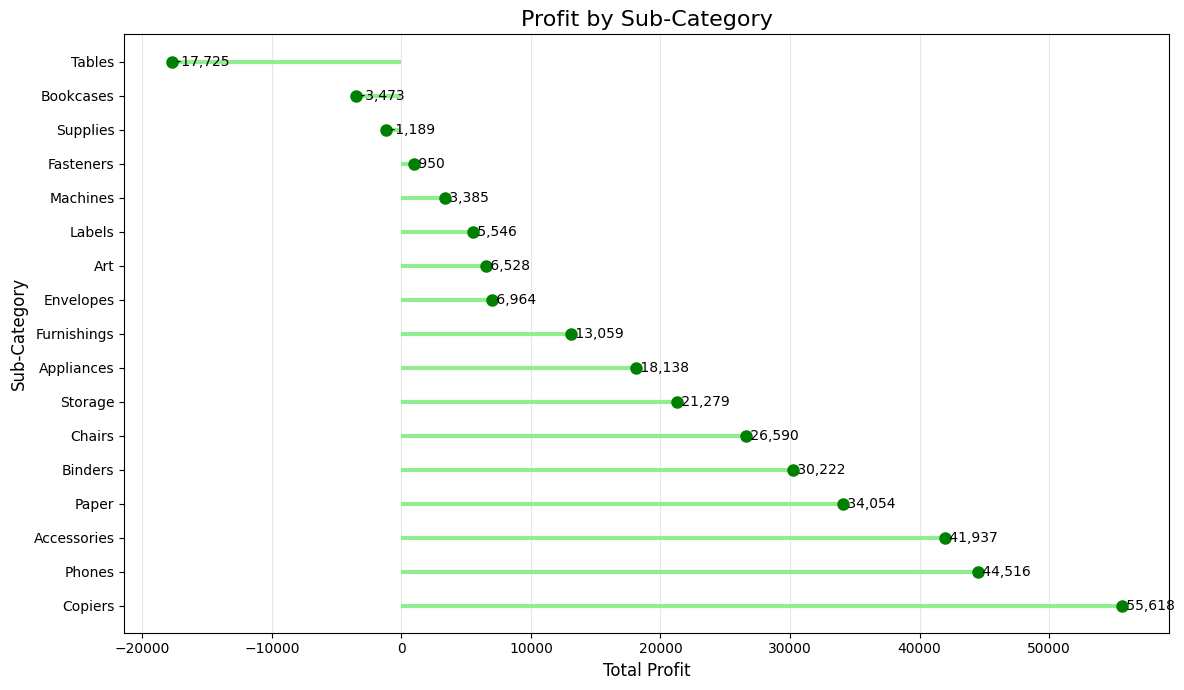

In [ ]:
b=data.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.hlines(y=b.index, xmin=0, xmax=b.values,
           color='lightgreen', linewidth=3)

plt.plot(b.values, b.index, 'o', color='green', markersize=8)

for i, value in enumerate(b.values):
    plt.text(value, i, f' {value:,.0f}', va='center', fontsize=10)

plt.title('Profit by Sub-Category', fontsize=16)
plt.xlabel('Total Profit', fontsize=12)
plt.ylabel('Sub-Category', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()



chart 7

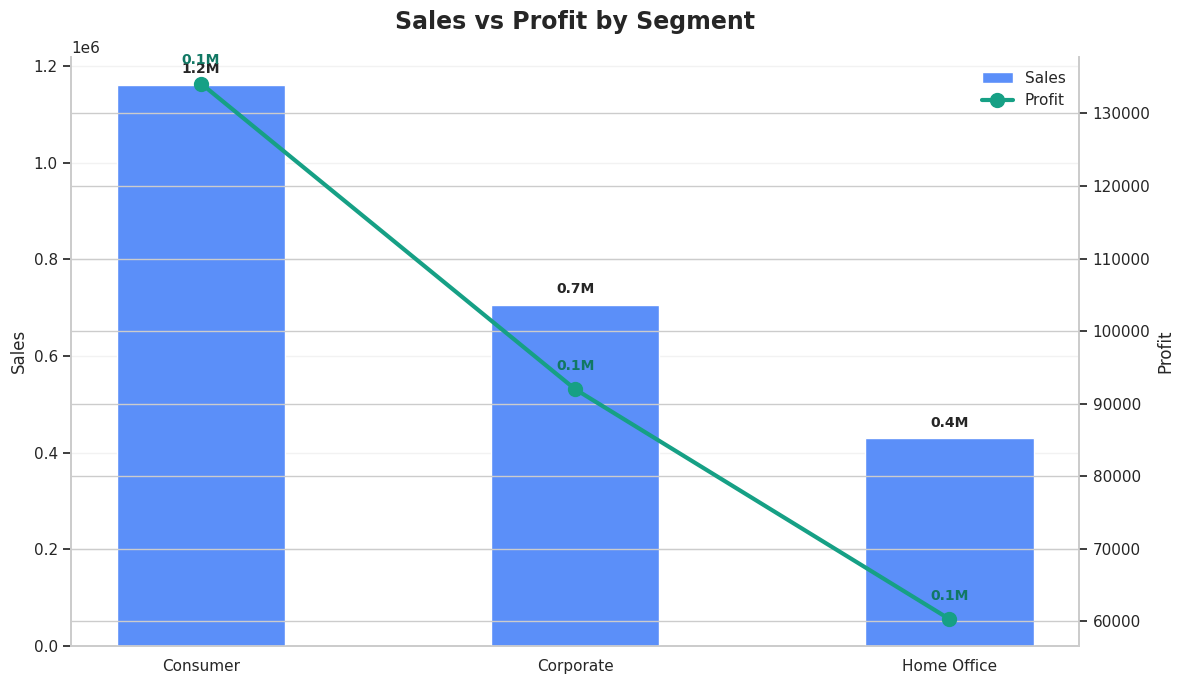

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

b = data.groupby('Segment')[['Sales', 'Profit']].sum()

fig, ax1 = plt.subplots(figsize=(12, 7))

x = np.arange(len(b))

# Sales columns
bars = ax1.bar(
    x, b['Sales'],
    width=0.45,
    color='#5B8FF9',
    label='Sales',
    zorder=3
)

ax1.set_ylabel('Sales', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(b.index, fontsize=11)

# Sales values
ax1.bar_label(
    bars,
    labels=[f'{v/1e6:.1f}M' for v in b['Sales']],
    padding=6,
    fontsize=10,
    fontweight='bold'
)

# Profit line on secondary axis
ax2 = ax1.twinx()

ax2.plot(
    x, b['Profit'],
    color='#16A085',
    marker='o',
    markersize=10,
    linewidth=3,
    label='Profit',
    zorder=5
)

# Profit values
for i, value in enumerate(b['Profit']):
    ax2.annotate(
        f'{value/1e6:.1f}M',
        (x[i], value),
        xytext=(0, 14),
        textcoords='offset points',
        ha='center',
        fontsize=10,
        fontweight='bold',
        color='#117864'
    )

ax1.set_title(
    'Sales vs Profit by Segment',
    fontsize=17,
    fontweight='bold',
    pad=20
)

ax2.set_ylabel('Profit', fontsize=12)

# Combined legend
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()

ax1.legend(
    h1 + h2, l1 + l2,
    loc='upper right',
    frameon=False
)

ax1.grid(axis='y', alpha=0.25)
ax1.grid(axis='x', visible=False)

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

ax1.set_axisbelow(True)

plt.tight_layout()
plt.show()



#sales by profit margin

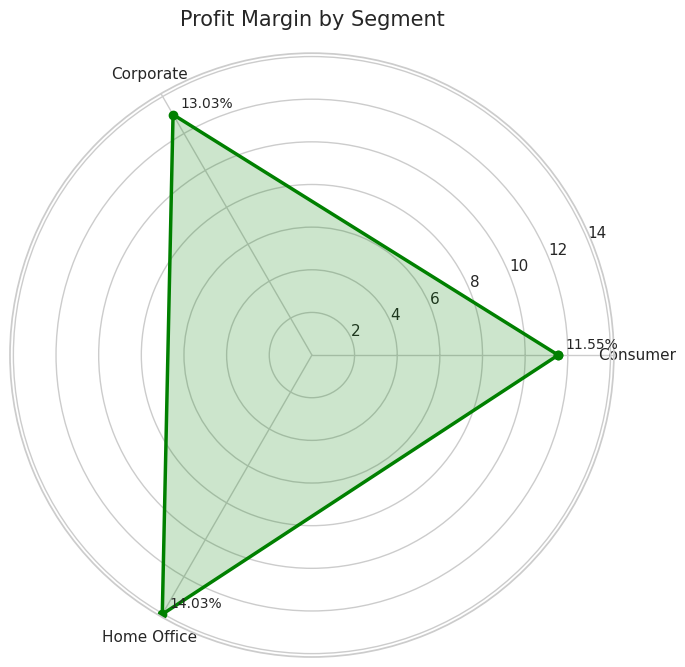